In [1]:
import gzip
from pickletools import optimize
from typing import Sequence
from xml.etree.ElementPath import prepare_self

import kagglehub
from fontTools.misc.textTools import tostr
from numpy.ma.core import shape
from pandas.io.sas.sas_constants import magic
from pydantic_core.core_schema import str_schema

kagglehub.login()


In [2]:
import kaggle
print("Kaggle installed successfully")

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token
Kaggle installed successfully


In [3]:
import os

# Open your downloaded kaggle.json file and copy-paste your credentials here:
os.environ["KAGGLE_USERNAME"] = "your_kaggle_username"
os.environ["KAGGLE_KEY"] = "your_kaggle_api_key"


In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hojjatk/mnist-dataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Rushabh\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1


In [5]:
import os

data_path = r"C:\Users\Rushabh\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1"

print(os.listdir(data_path))

['t10k-images-idx3-ubyte', 't10k-images.idx3-ubyte', 't10k-labels-idx1-ubyte', 't10k-labels.idx1-ubyte', 'train-images-idx3-ubyte', 'train-images.idx3-ubyte', 'train-labels-idx1-ubyte', 'train-labels.idx1-ubyte']


In [6]:
import os

data_path = r"C:\Users\Rushabh\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1"

for file in os.listdir(data_path):
    file_path = os.path.join(data_path, file)
    size_mb = os.path.getsize(file_path) / (1024 * 1024)
    print(f"{file}: {size_mb:.2f} MB")

t10k-images-idx3-ubyte: 0.00 MB
t10k-images.idx3-ubyte: 7.48 MB
t10k-labels-idx1-ubyte: 0.00 MB
t10k-labels.idx1-ubyte: 0.01 MB
train-images-idx3-ubyte: 0.00 MB
train-images.idx3-ubyte: 44.86 MB
train-labels-idx1-ubyte: 0.00 MB
train-labels.idx1-ubyte: 0.06 MB


In [7]:
import numpy as np
import pandas as pd
import struct
label_file = os.path.join(data_path, "train-labels.idx1-ubyte")

with open(label_file, "rb") as f:
    magic, num_labels = struct.unpack(">II", f.read(8))
    labels = np.frombuffer(f.read(), dtype=np.uint8)

df = pd.DataFrame({"label": labels})

df.head()


,label
0,5
1,0
2,4
3,1
4,9


In [8]:
print("%" * 50)
print(df.head(10))
print("%" * 50)
print(df.shape)
print("%" * 50)
print(df.isnull().sum())
print("%" * 50)
print(df.describe())
print("%" * 50)
print(df["label"].value_counts().sort_index())
print("%" * 50)
print(len(df))
print("%" * 50)
print(df.dtypes)
print("%" * 50)
print(df.min())
print("%" * 50)
print(df.max())

%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
   label
0      5
1      0
2      4
3      1
4      9
5      2
6      1
7      3
8      1
9      4
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
(60000, 1)
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
label    0
dtype: int64
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
              label
count  60000.000000
mean       4.453933
std        2.889270
min        0.000000
25%        2.000000
50%        4.000000
75%        7.000000
max        9.000000
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
label
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
60000
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
label    uint8
dtype: object
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
label    0
dtype: uint8
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
label    9
dtype: uint8


In [9]:

import os
import struct
import numpy as np

# 1. Point to the uncompressed image and label files
image_file_path = os.path.join(path, "train-images.idx3-ubyte")
label_file_path = os.path.join(path, "train-labels.idx1-ubyte")

print("Decoding data streams from your Kaggle local cache...")

# 2. Read the 16-byte image header
with open(image_file_path, "rb") as f:
    magic_img, num_images, rows, cols = struct.unpack(">IIII", f.read(16))

    # 3. Load image pixels into a 3D NumPy array
    images = np.frombuffer(
        f.read(), dtype=np.uint8
    ).reshape(num_images, rows, cols)

# 4. Read the 8-byte label header
with open(label_file_path, "rb") as f:
    magic_lbl, num_labels = struct.unpack(">II", f.read(8))
    labels = np.frombuffer(f.read(), dtype=np.uint8)

# 5. Verify the data
print("\nVerification Complete!")
print(f"Image magic number: {magic_img}")
print(f"Label magic number: {magic_lbl}")
print(f"Number of images: {num_images}")
print(f"Number of labels: {num_labels}")
print(f"Resolution per image: {rows} x {cols}")
print(f"NumPy image dimensions: {images.shape}")
print(f"NumPy label dimensions: {labels.shape}")
print(f"Image-label counts match: {num_images == num_labels}")


Decoding data streams from your Kaggle local cache...

Verification Complete!
Image magic number: 2051
Label magic number: 2049
Number of images: 60000
Number of labels: 60000
Resolution per image: 28 x 28
NumPy image dimensions: (60000, 28, 28)
NumPy label dimensions: (60000,)
Image-label counts match: True


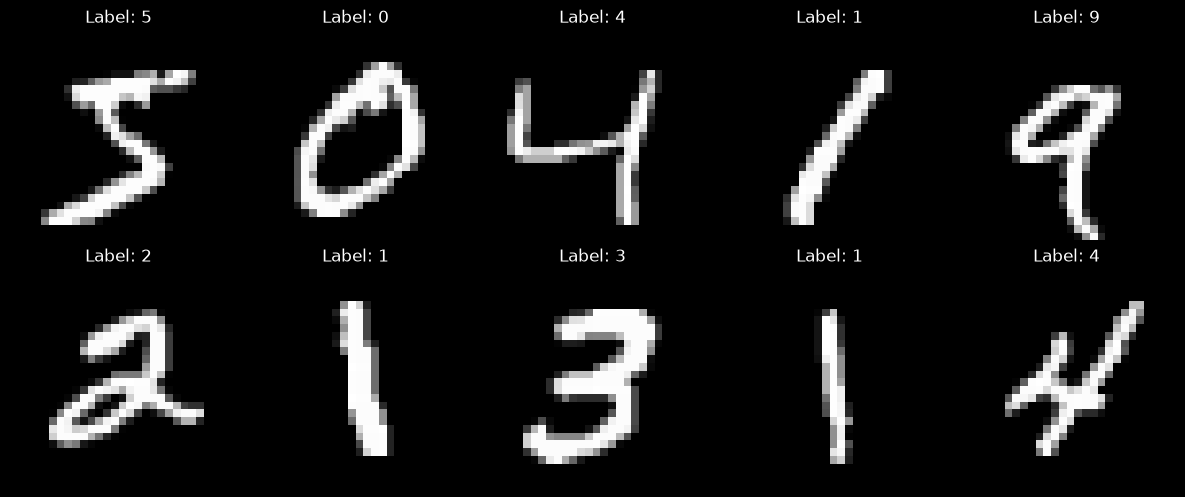

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5 ,figsize=(12,5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Label: {labels[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()


In [11]:
import os
import csv
import struct
import numpy as np
import pandas as pd

images_file = os.path.join(path, "train-images.idx3-ubyte")

with open(images_file, "rb") as f:
    magic_img, num_images, rows, cols = struct.unpack(">IIII", f.read(16))
    images = np.frombuffer(f.read(), dtype=np.uint8).reshape(num_images, rows, cols)


print("\nVerification Complete!")
print(f"Image magic number: {magic_img}")
print(f"Number of images: {num_images}")
print(f"Shape of images: {images.shape}")
print(f"Data type used to store pixels: {images.dtype}")
print(f"The lowest pixel: {images.min()}")
print(f"The highest pixel: {images.max()}")




Verification Complete!
Image magic number: 2051
Number of images: 60000
Shape of images: (60000, 28, 28)
Data type used to store pixels: uint8
The lowest pixel: 0
The highest pixel: 255


In [12]:
images = images.astype(np.float32)
images = images / 255.0


In [13]:
print(images.dtype)
print(images.max())
print(images.min())

float32
1.0
0.0


In [14]:
import torch

images = torch.from_numpy(images)
labels = torch.from_numpy(np.copy(labels))



In [15]:
print(images.dtype)
print(labels.dtype)

torch.float32
torch.uint8


In [16]:
labels = labels.long()
print(labels.dtype)

torch.int64


In [17]:
images = images.unsqueeze(dim = 1)
print(images.shape)

torch.Size([60000, 1, 28, 28])


In [18]:
from sklearn.model_selection import train_test_split
X = images
y = labels

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    shuffle=True,
    random_state = 42,
    stratify = y
)

In [19]:
print("The shape of X_train: ", X_train.shape)
print("The shape of X_test", X_test.shape)
print("The shape of y_train", y_train.shape)
print("The shape of y_test", y_test.shape)

The shape of X_train:  torch.Size([48000, 1, 28, 28])
The shape of X_test torch.Size([12000, 1, 28, 28])
The shape of y_train torch.Size([48000])
The shape of y_test torch.Size([12000])


In [20]:
import torchvision
from torch.utils.data import DataLoader,TensorDataset

tensor_dataset = TensorDataset(X_train,y_train)
BATCH_SIZE = 64

train_loader = DataLoader(
    tensor_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    drop_last=True
)

In [21]:
images_batch, labels_batch = next(iter(train_loader))

print("The shape of the images_batch is:", images_batch.shape)
print("The shape of labels_batch is:", labels_batch.shape)

The shape of the images_batch is: torch.Size([64, 1, 28, 28])
The shape of labels_batch is: torch.Size([64])


In [22]:
import torch.nn as nn

model = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32,3,padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64,3,padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(64, 128,3,padding=1), nn.BatchNorm2d(128), nn.ReLU(),
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Dropout(0.25),
    nn.Linear(128, 256),
    nn.ReLU(),
    nn.Dropout(0.25),
    nn.Linear(256, 10)
)

In [23]:
import torch

dummy_input = torch.randn(64, 1, 28, 28)

output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [24]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [25]:
model.train()
for batch_idx, (images, labels) in enumerate(train_loader):
    optimizer.zero_grad()
    outputs = model(images)
    loss = loss_fn(outputs, labels)
    loss.backward()
    optimizer.step()


In [26]:
epochs = 10

for epoch in range(epochs):

    # Training phase
    model.train()
    total_train_loss = 0.0

    for images, labels in train_loader:

        optimizer.zero_grad()

        y_logits = model(images)
        loss_value = loss_fn(y_logits, labels)

        loss_value.backward()
        optimizer.step()

        total_train_loss += loss_value.item()

    avg_train_loss = total_train_loss / len(train_loader)

    model.eval()
    total_correct = 0
    total_samples = 0

    with torch.inference_mode():
        for images, labels in train_loader:

            val_logits = model(images)
            val_pred = torch.argmax(val_logits, dim=1)

            total_correct += (val_pred == labels).sum().item()
            total_samples += labels.size(0)

    val_accuracy = total_correct / total_samples

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch 1/10 | Train Loss: 0.0570 | Val Accuracy: 0.9901
Epoch 2/10 | Train Loss: 0.0421 | Val Accuracy: 0.9913
Epoch 3/10 | Train Loss: 0.0352 | Val Accuracy: 0.9949
Epoch 4/10 | Train Loss: 0.0322 | Val Accuracy: 0.9966
Epoch 5/10 | Train Loss: 0.0260 | Val Accuracy: 0.9944
Epoch 6/10 | Train Loss: 0.0208 | Val Accuracy: 0.9960
Epoch 7/10 | Train Loss: 0.0221 | Val Accuracy: 0.9953
Epoch 8/10 | Train Loss: 0.0204 | Val Accuracy: 0.9974
Epoch 9/10 | Train Loss: 0.0186 | Val Accuracy: 0.9964
Epoch 10/10 | Train Loss: 0.0171 | Val Accuracy: 0.9982


In [27]:
best_val_acc = 0.0

if val_accuracy > best_val_acc:
    best_val_acc = val_accuracy

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_accuracy": best_val_acc
    }, "best_mnist_cnn.pth")

    print("Best model saved!")

Best model saved!


In [28]:
checkpoint = torch.load(
    "best_mnist_cnn.pth",
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best validation accuracy:", checkpoint["val_accuracy"])

Best epoch: 10
Best validation accuracy: 0.9982291666666666


In [29]:
labels_file = os.path.join(path, "t10k-labels.idx1-ubyte")

with open(labels_file, "rb") as f:
    magic_labels, num_labels = struct.unpack(">II", f.read(8))
    test_labels = np.frombuffer(f.read(), dtype=np.uint8)

print("Label magic number:", magic_labels)
print("Number of labels:", num_labels)
print("Labels shape:", test_labels.shape)

Label magic number: 2049
Number of labels: 10000
Labels shape: (10000,)


In [30]:
images_file = os.path.join(path, "t10k-images.idx3-ubyte")

with open(images_file, "rb") as f:
    magic_img, num_images, rows, cols = struct.unpack(">IIII", f.read(16))
    test_img = np.frombuffer(f.read(), dtype=np.uint8)
    test_img = test_img.reshape(num_images, rows, cols)

print("Magic number:", magic_img)
print("Number of images:", num_images)
print("Image shape:", test_img.shape)
print("Data type:", test_img.dtype)
print("Minimum pixel:", test_img.min())
print("Maximum pixel:", test_img.max())

Magic number: 2051
Number of images: 10000
Image shape: (10000, 28, 28)
Data type: uint8
Minimum pixel: 0
Maximum pixel: 255


In [31]:
X_test = torch.from_numpy(test_img.copy()).float()
X_test = X_test.unsqueeze(dim = 1)/ 255.0

print(X_test.shape)
print(X_test.dtype)
print(X_test.min())
print(X_test.max())


torch.Size([10000, 1, 28, 28])
torch.float32
tensor(0.)
tensor(1.)


In [32]:
import os
import numpy as np
import struct
import torch

test_labels_file = os.path.join(path, "t10k-labels.idx1-ubyte")

with open(test_labels_file, "rb") as f:
    magic_labels, num_labels = struct.unpack(">II", f.read(8))
    test_labels = np.frombuffer(f.read(), dtype=np.uint8)

y_test = torch.from_numpy(test_labels.copy()).long()

print("Magic number:", magic_labels)
print("Number of labels:", num_labels)
print("Labels shape:", y_test.shape)
print("Data type:", y_test.dtype)

Magic number: 2049
Number of labels: 10000
Labels shape: torch.Size([10000])
Data type: torch.int64


In [33]:
from torch.utils.data import DataLoader,TensorDataset

tensor_dataset = TensorDataset(X_test,y_test)
BATCH_SIZE = 64
test_loader = DataLoader(
    tensor_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [34]:
model.eval()

total_correct = 0.0
total_samples = 0
total_loss = 0.0

with torch.inference_mode():
    for images, labels in test_loader:
        outputs = model(images)
        loss = loss_fn(outputs, labels)

        pred = torch.argmax(outputs, dim=1)

        total_correct += (pred == labels).sum().item()
        total_samples += labels.size(0)
        total_loss += loss.item() * labels.size(0)
test_accuracy = total_correct / total_samples
test_loss = total_loss / total_samples

print(f"Test Accuracy: {test_accuracy:.4%}")
print(f"Test Loss: {test_loss:.4f}")


Test Accuracy: 99.0600%
Test Loss: 0.0294


In [35]:
import torch

model.eval()

wrong_images = []
wrong_labels = []
wrong_pred = []

with torch.inference_mode():
    for images, labels in test_loader:
        output = model(images)
        predictions = output.argmax(dim = 1)

        wrong_mask = predictions != labels

        wrong_images.extend(images[wrong_mask].cpu())
        wrong_labels.extend(labels[wrong_mask].cpu())
        wrong_pred.extend(predictions[wrong_mask].cpu().tolist())
print("Total incorrect images: ", len(wrong_images))


Total incorrect images:  94


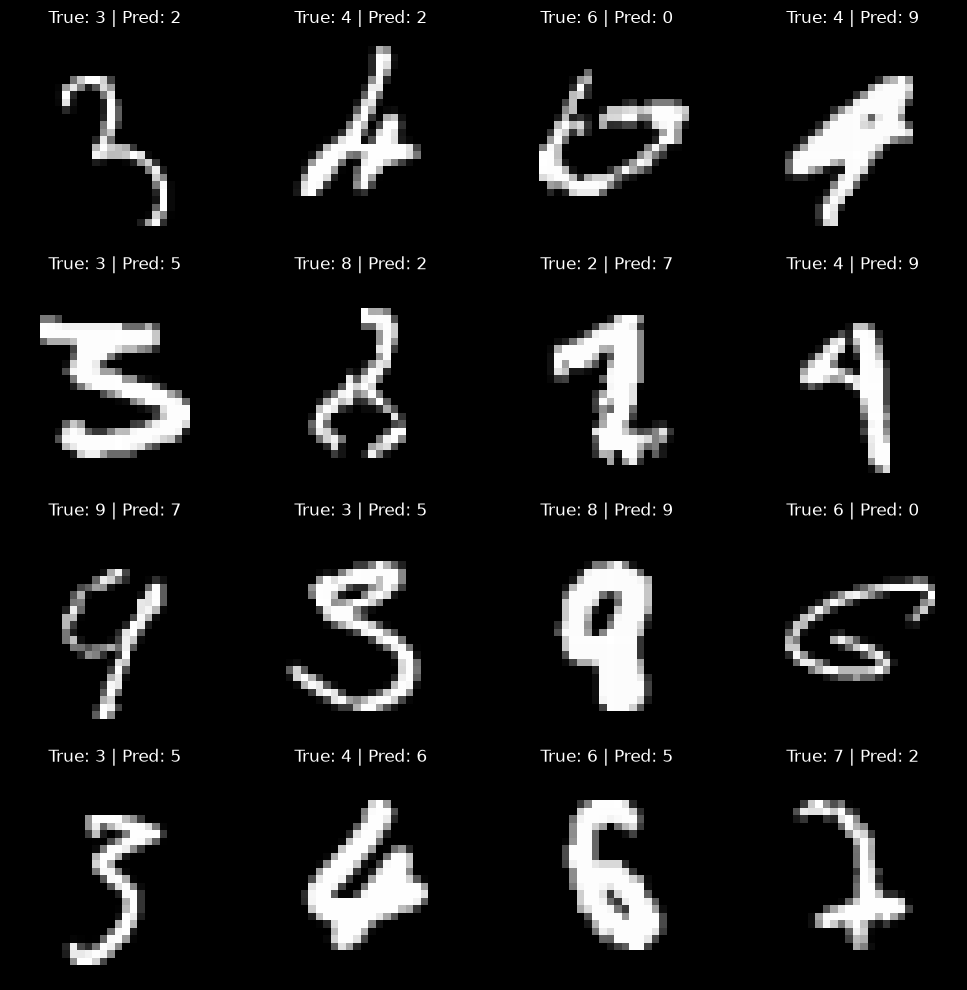

In [38]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(wrong_images[i].squeeze(), cmap="gray")
    ax.set_title(
        f"True: {wrong_labels[i]} | Pred: {wrong_pred[i]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [40]:

# Count True 3 predicted as 5
three_as_five = sum(
    1 for true, pred in zip(wrong_labels, wrong_pred)
    if true == 3 and pred == 5
)

# Count True 5 predicted as 3
five_as_three = sum(
    1 for true, pred in zip(wrong_labels, wrong_pred)
    if true == 5 and pred == 3
)

print("True 3 predicted as 5:", three_as_five)
print("True 5 predicted as 3:", five_as_three)
print("Total 3 vs 5 confusions:", three_as_five + five_as_three)


True 3 predicted as 5: 6
True 5 predicted as 3: 4
Total 3 vs 5 confusions: 10


Found 6 images matching True 3 predicted as 5.


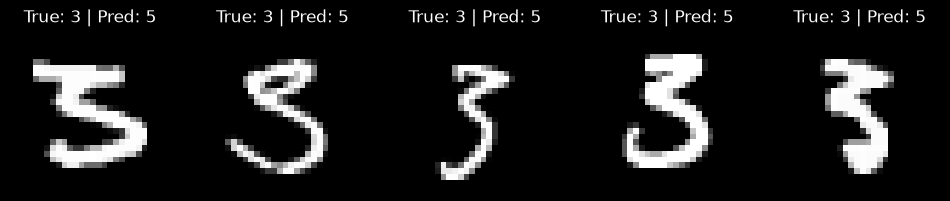

In [41]:
import matplotlib.pyplot as plt
import numpy as np

# Convert to numpy arrays for easier boolean indexing if they aren't already
wrong_images_np = np.array(wrong_images)
wrong_labels_np = np.array(wrong_labels)
wrong_predictions_np = np.array(wrong_pred)

# Create the mask for True 3 predicted as 5
mask = (wrong_labels_np == 3) & (wrong_predictions_np == 5)

# Filter the arrays
filtered_images = wrong_images_np[mask]
filtered_labels = wrong_labels_np[mask]
filtered_preds = wrong_predictions_np[mask]

print(f"Found {len(filtered_images)} images matching True 3 predicted as 5.")

# Plot the filtered images
fig, axes = plt.subplots(1, min(5, len(filtered_images)), figsize=(12, 3))
if len(filtered_images) == 1:
    axes = [axes]

for i, ax in enumerate(axes[:len(filtered_images)]):
    ax.imshow(filtered_images[i].squeeze(), cmap='gray')
    ax.set_title(f"True: {filtered_labels[i]} | Pred: {filtered_preds[i]}")
    ax.axis('off')
plt.show()


In [47]:

true_label = []
pred_label = []

for images,labels in test_loader:
    outputs = model(images)
    pred = outputs.argmax(dim = 1)
    pred_label.extend(pred)
    true_label.extend(labels)


In [48]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(true_label, pred_label)
print(cm)

[[ 976    0    1    0    0    0    2    1    0    0]
 [   0 1134    0    0    0    0    0    1    0    0]
 [   1    0 1030    0    0    0    0    1    0    0]
 [   0    0    3  997    0    6    0    2    1    1]
 [   0    0    3    0  963    0    1    2    1   12]
 [   2    0    0    4    0  883    1    0    0    2]
 [   4    3    0    0    0    4  947    0    0    0]
 [   0    3    8    0    0    0    0 1016    1    0]
 [   1    0    2    0    0    1    0    0  965    5]
 [   1    0    0    0    4    3    0    5    1  995]]


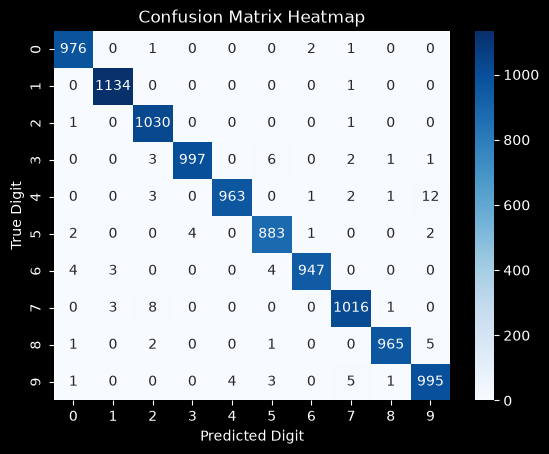

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(
    cm,
    annot=True,
    cmap="Blues",
    fmt="d",
    xticklabels=list(range(10)),
    yticklabels=list(range(10)),
)
plt.xlabel('Predicted Digit')
plt.ylabel('True Digit')
plt.title('Confusion Matrix Heatmap')
plt.show()
